# Does the near-unanimous cutoff change the prediction results?

Every result in notebooks [01](01_model_comparison.ipynb) and [02](02_member_states.ipynb) drops near-unanimous roll calls, where the smaller side has under 2.5% of those voting. That cutoff is computed from the final vote. On roll calls where both parties' majorities agree, the smaller side is mostly defectors, so the cutoff partly decides which of those roll calls are kept: a higher cutoff keeps only those with more defectors.

Here every model is refitted at 1% and 5%, with the same features, time split (train 1991 to 2010, validation 2011 to 2014, test 2015 to 2024) and settings as the standard run. Only seed 0 of the GRU is fitted at each cutoff. Four questions:

1. Does accuracy still beat the party line, and does the ladder (own past rate < logistic regression < boosting < GRU) hold at each cutoff?
2. Are the steps larger than chance at each cutoff, including the two subset findings (the GRU's marginal AUC gain on party-opposed roll calls and boosting not beating logistic regression where the parties agree)?
3. Do changes come from which test votes are scored, or from refitting the models (training data, history features, early stopping)?
4. Do the "two behaviours" of defection hold?

All results describe voting behaviour on roll calls that reached the floor.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

sys.path.append(str(Path.cwd().parents[1] / "data_loading"))
from voteview import load_members

warnings.filterwarnings("ignore")
NEUTRAL = "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#b5b4ad",
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e6e5df", "grid.linewidth": 0.8,
    "lines.linewidth": 2, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "text.color": "#0b0b0b", "xtick.color": NEUTRAL, "ytick.color": NEUTRAL,
    "legend.frameon": False,
})
OUTPUTS = Path.cwd().parent / "outputs"
SOURCES = {"1%": OUTPUTS / "cutoff_0.01", "2.5% (standard)": OUTPUTS, "5%": OUTPUTS / "cutoff_0.05"}
CUTOFFS = list(SOURCES)
MODELS = ["own_past_rate", "logistic", "boosting", "gru_seed0", "boosting_with_split"]
NAMES = {"own_past_rate": "Own past rate", "logistic": "Logistic regression", "boosting": "Gradient boosting",
         "gru_seed0": "GRU, seed 0", "boosting_with_split": "Boosting + split sizes (after the vote)"}
MODEL_COLORS = {"own_past_rate": NEUTRAL, "logistic": "#2a78d6", "boosting": "#eb6834", "gru_seed0": "#1baf7a"}
KEYS = ["congress", "chamber", "rollnumber"]
columns = KEYS + ["person", "party", "split", "party_opposed", "defected"] + [f"p_{m}" for m in MODELS]
tests = {}
for cutoff, folder in SOURCES.items():
    frame = pd.read_parquet(folder / "predictions.parquet", columns=columns)
    frame = frame[frame["split"] == "test"].reset_index(drop=True)
    frame["defected"] = frame["defected"].astype(bool)
    frame["kind"] = np.where(frame["party_opposed"], "party-opposed", "parties agree")
    tests[cutoff] = frame
rows = []
for cutoff, t in tests.items():
    rows.append({"cutoff": cutoff, "votes": len(t), "roll calls": t[KEYS].drop_duplicates().shape[0],
                 "% votes on party-opposed roll calls": t["party_opposed"].mean() * 100,
                 "defection rate %": t["defected"].mean() * 100,
                 "defection rate %, party-opposed": t.loc[t["party_opposed"], "defected"].mean() * 100,
                 "defection rate %, parties agree": t.loc[~t["party_opposed"], "defected"].mean() * 100,
                 "% of defections on roll calls where parties agree": (t["defected"] & ~t["party_opposed"]).sum() / t["defected"].sum() * 100,
                 "party-line accuracy %": (1 - t["defected"].mean()) * 100,
                 "party-line accuracy %, party-opposed": (1 - t.loc[t["party_opposed"], "defected"].mean()) * 100})
print("Test years, 2015 to 2024. The smaller side of a roll call must be at least the cutoff share of those voting.")
display(pd.DataFrame(rows).set_index("cutoff").round(2).T)

Test years, 2015 to 2024. The smaller side of a roll call must be at least the cutoff share of those voting.


cutoff,1%,2.5% (standard),5%
votes,2412349.00,2319540.00,2220715.00
roll calls,8362.00,8027.00,7713.00
% votes on party-opposed roll calls,77.11,80.19,83.76
defection rate %,6.20,6.38,6.51
"defection rate %, party-opposed",4.72,4.72,4.72
"defection rate %, parties agree",11.19,13.12,15.71
% of defections on roll calls where parties agree,41.30,40.70,39.22
party-line accuracy %,93.80,93.62,93.49
"party-line accuracy %, party-opposed",95.28,95.28,95.28


**What the cutoff changes.** Going from 1% to 5% drops 649 of 8,362 test roll calls (8%) and 8% of test votes. Almost all of them are roll calls where the parties agree:

- The party-opposed numbers don't move: the defection rate is 4.72% and party-line accuracy 95.28% at every cutoff. A roll call where the party majorities split almost never has a smaller side under 5%.
- Where the parties agree, the defection rate rises from 11.2% to 13.1% to 15.7%, because a higher cutoff keeps only the roll calls with more defectors. This is the selection on the outcome described above.
- Over all votes, the defection rate (6.2% to 6.5%) and party-line accuracy (93.8% to 93.5%) change little. Roll calls where the parties agree hold 39% to 41% of all defections at every cutoff.

## Does accuracy still beat the party line?

In [ ]:
accuracy = {}
for cutoff, folder in SOURCES.items():
    metrics = pd.read_csv(folder / "test_metrics.csv", index_col=0)
    accuracy[cutoff] = metrics.loc[["party_line", "logistic", "boosting", "gru_seed0"],
                                   ["vote_accuracy", "vote_accuracy_party_opposed"]] * 100
accuracy = pd.concat(accuracy, axis=1).rename(index={"party_line": "Everyone votes with their party", **NAMES})
accuracy.columns = accuracy.columns.set_names(["cutoff", "votes"]).set_levels(
    ["all votes", "party-opposed"], level="votes")
print("Vote accuracy (%) on the test years, against the party-line baseline\n")
print(accuracy.round(2).swaplevel(axis=1).sort_index(axis=1).to_string())

Vote accuracy (%) on the test years, against the party-line baseline

votes                           all votes                        party-opposed                       
cutoff                                 1% 2.5% (standard)     5%            1% 2.5% (standard)     5%
Everyone votes with their party     93.80           93.62  93.49         95.28           95.28  95.28
Logistic regression                 94.09           93.96  93.91         95.40           95.40  95.40
Gradient boosting                   94.13           94.00  93.91         95.46           95.47  95.47
GRU, seed 0                         94.30           94.18  94.10         95.55           95.55  95.56


**Accuracy still beats the party line by a small margin at every cutoff.** The GRU (seed 0) gains 0.5 to 0.6 points over all votes (94.30% against 93.80% at 1%, 94.10% against 93.49% at 5%) and about 0.3 points on party-opposed roll calls (95.55% to 95.56% against 95.28%). Logistic regression and boosting gain less. The gain over the party line is about the same size at every cutoff, so the cutoff doesn't change the accuracy result either.

## Does the model ladder hold at each cutoff?

AUC on the test years, by cutoff and kind of roll call


subset,all votes,party-opposed,parties agree,all votes,party-opposed,parties agree,all votes,party-opposed,parties agree
cutoff,1%,1%,1%,2.5% (standard),2.5% (standard),2.5% (standard),5%,5%,5%
model,,,,,,,,,
Own past rate,0.7672,0.7346,0.7796,0.7734,0.7346,0.7829,0.7787,0.7346,0.7808
Logistic regression,0.8284,0.8031,0.8325,0.8305,0.8036,0.8256,0.8322,0.8041,0.8129
Gradient boosting,0.8481,0.8380,0.8293,0.8497,0.8375,0.8187,0.8525,0.8378,0.8078
"GRU, seed 0",0.8541,0.8388,0.8507,0.8542,0.8391,0.8366,0.8565,0.8392,0.8248
Boosting + split sizes (after the vote),0.9538,0.9611,0.9341,0.9529,0.9609,0.9245,0.9526,0.9606,0.9124


AP on the test years, by cutoff and kind of roll call


subset,all votes,party-opposed,parties agree,all votes,party-opposed,parties agree,all votes,party-opposed,parties agree
cutoff,1%,1%,1%,2.5% (standard),2.5% (standard),2.5% (standard),5%,5%,5%
model,,,,,,,,,
Own past rate,0.2512,0.1493,0.3738,0.2695,0.1493,0.4144,0.2853,0.1493,0.4556
Logistic regression,0.3492,0.2832,0.4354,0.3622,0.2830,0.4657,0.3740,0.2836,0.4980
Gradient boosting,0.3669,0.3196,0.4366,0.3794,0.3205,0.4591,0.3904,0.3198,0.4907
"GRU, seed 0",0.4052,0.3425,0.4889,0.4091,0.3392,0.5085,0.4210,0.3422,0.5313
Boosting + split sizes (after the vote),0.6105,0.6048,0.6554,0.6084,0.6026,0.6574,0.6054,0.6012,0.6605


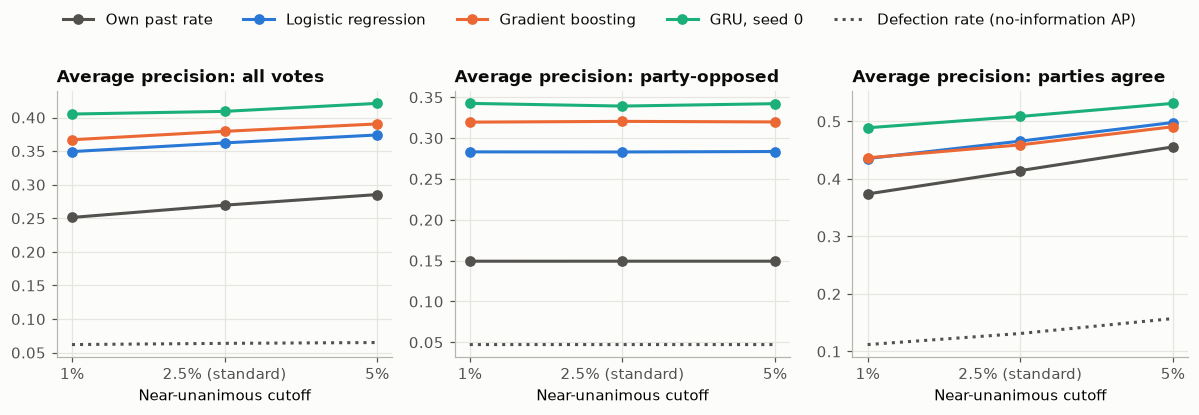

In [2]:
class Ranked:
    """Weighted AUC and average precision from one sort; equal to sklearn's with sample_weight, ties included."""

    def __init__(self, p, y):
        values, self.group = np.unique(-p, return_inverse=True)
        self.n, self.y = len(values), y

    def scores(self, w=None):
        w = np.ones(len(self.y)) if w is None else w
        pos = np.bincount(self.group, weights=w * self.y, minlength=self.n)
        neg = np.bincount(self.group, weights=w * (1 - self.y), minlength=self.n)
        tp, fp = np.cumsum(pos), np.cumsum(neg)
        auc = (pos * (fp[-1] - fp) + 0.5 * pos * neg).sum() / (tp[-1] * fp[-1])
        ap = (pos / tp[-1] * tp / np.maximum(tp + fp, 1e-300)).sum()
        return auc, ap


SUBSETS = {"all votes": lambda t: np.ones(len(t), bool), "party-opposed": lambda t: t["party_opposed"].to_numpy(),
           "parties agree": lambda t: ~t["party_opposed"].to_numpy()}
records = []
for cutoff, t in tests.items():
    for subset, select in SUBSETS.items():
        part = t[select(t)]
        y = part["defected"].to_numpy().astype(float)
        for m in MODELS:
            auc, ap = Ranked(part[f"p_{m}"].to_numpy(), y).scores()
            records.append({"cutoff": cutoff, "subset": subset, "model": NAMES[m], "AUC": auc, "AP": ap, "no-information AP": y.mean()})
ladder = pd.DataFrame(records)
for metric in ["AUC", "AP"]:
    print(f"{metric} on the test years, by cutoff and kind of roll call")
    display(ladder.pivot_table(index="model", columns=["subset", "cutoff"], values=metric, sort=False)
            .reindex(columns=CUTOFFS, level="cutoff").round(4))
fig, axes = plt.subplots(1, 3, figsize=(11, 3.8), sharey=False)
for axis, subset in zip(axes, SUBSETS):
    part = ladder[ladder["subset"] == subset]
    for m in ["own_past_rate", "logistic", "boosting", "gru_seed0"]:
        line = part[part["model"] == NAMES[m]].set_index("cutoff").loc[CUTOFFS]
        axis.plot(range(3), line["AP"], marker="o", color=MODEL_COLORS[m], label=NAMES[m])
    base = part[part["model"] == NAMES["logistic"]].set_index("cutoff").loc[CUTOFFS]
    axis.plot(range(3), base["no-information AP"], color=NEUTRAL, linestyle=":", label="Defection rate (no-information AP)")
    axis.set_xticks(range(3), CUTOFFS)
    axis.set_title(f"Average precision: {subset}")
    axis.set_xlabel("Near-unanimous cutoff")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=5)
fig.tight_layout(rect=(0, 0, 1, 0.88))
plt.show()

**The ladder holds at every cutoff.** Over all votes, each model ranks defections better than the one below it, at 1%, 2.5% and 5%, on both AUC and average precision. In the figure the lines run almost parallel:

- **Party-opposed (middle panel):** results are practically identical at all three cutoffs, since these are almost the same votes. The small differences (AUC within 0.001) come from refitting the models.
- **Parties agree (right panel):** average precision rises with the cutoff for every model, as does the no-information line (the defection rate). At the same time, the AUC of every fitted model falls (boosting 0.829 to 0.808, GRU 0.851 to 0.825), while the own past rate stays flat (0.780 to 0.783). So the levels on these roll calls depend on the cutoff and can't be compared across cutoffs; the order of models can. The GRU is first at every cutoff. Logistic regression and boosting are close at every cutoff, and boosting is never clearly ahead.
- **All votes (left panel):** average precision rises mildly, from the parties-agree part. AUC also rises slightly (own past rate 0.767 to 0.779), because the share of votes on party-opposed roll calls grows from 77% to 84%: a change of mix, not of the models.

The after-the-vote reference (boosting with split sizes) stays at AUC 0.953 to 0.954 over all votes. As in notebook 01, it isn't a forecast.

## Are the differences larger than chance at each cutoff?

In [3]:
# Paired differences, resampling roll calls and members together, as in notebook 01.
PAIRS = [("gru_seed0", "boosting"), ("boosting", "logistic"), ("logistic", "own_past_rate")]
REPS = 1000
rows = []
for cutoff, t in tests.items():
    for subset, select in SUBSETS.items():
        part = t[select(t)]
        y = part["defected"].to_numpy().astype(float)
        rollcall = part.groupby(KEYS).ngroup().to_numpy()
        member = part.groupby("person").ngroup().to_numpy()
        n_r, n_m = rollcall.max() + 1, member.max() + 1
        models = sorted({m for pair in PAIRS for m in pair})
        ranked = {m: Ranked(part[f"p_{m}"].to_numpy(), y) for m in models}
        point = {m: ranked[m].scores() for m in models}
        rng = np.random.default_rng(0)
        draws = {m: [] for m in models}
        for _ in range(REPS):
            w = (np.bincount(rng.integers(0, n_r, n_r), minlength=n_r)[rollcall]
                 * np.bincount(rng.integers(0, n_m, n_m), minlength=n_m)[member]).astype(float)
            for m in models:
                draws[m].append(ranked[m].scores(w))
        for a, b in PAIRS:
            diff = np.array(draws[a]) - np.array(draws[b])
            low, high = np.percentile(diff, [2.5, 97.5], axis=0)
            rows.append({"cutoff": cutoff, "subset": subset, "comparison": f"{NAMES[a]} minus {NAMES[b]}",
                         "AUC difference": point[a][0] - point[b][0], "AUC 95% low": low[0], "AUC 95% high": high[0],
                         "AP difference": point[a][1] - point[b][1], "AP 95% low": low[1], "AP 95% high": high[1]})
differences = pd.DataFrame(rows)
print(f"Paired differences on the test years, 95% intervals from {REPS} draws resampling roll calls and members together")
for comparison, part in differences.groupby("comparison", sort=False):
    print(comparison)
    display(part.drop(columns="comparison").set_index(["subset", "cutoff"]).round(4))

Paired differences on the test years, 95% intervals from 1000 draws resampling roll calls and members together
GRU, seed 0 minus Gradient boosting


,,AUC difference,AUC 95% low,AUC 95% high,AP difference,AP 95% low,AP 95% high
subset,cutoff,,,,,,
all votes,1%,0.0060,0.0029,0.0090,0.0383,0.0304,0.0469
party-opposed,1%,0.0008,-0.0032,0.0047,0.0230,0.0144,0.0315
parties agree,1%,0.0214,0.0148,0.0288,0.0522,0.0368,0.0680
all votes,2.5% (standard),0.0045,0.0014,0.0075,0.0297,0.0218,0.0387
party-opposed,2.5% (standard),0.0015,-0.0022,0.0056,0.0187,0.0090,0.0280
parties agree,2.5% (standard),0.0179,0.0111,0.0253,0.0494,0.0353,0.0633
all votes,5%,0.0040,0.0009,0.0068,0.0306,0.0228,0.0387
party-opposed,5%,0.0014,-0.0025,0.0053,0.0224,0.0131,0.0314
parties agree,5%,0.0169,0.0094,0.0245,0.0406,0.0253,0.0564


Gradient boosting minus Logistic regression


,,AUC difference,AUC 95% low,AUC 95% high,AP difference,AP 95% low,AP 95% high
subset,cutoff,,,,,,
all votes,1%,0.0197,0.0162,0.0232,0.0176,0.0104,0.0246
party-opposed,1%,0.0349,0.0292,0.0414,0.0364,0.0290,0.0434
parties agree,1%,-0.0031,-0.0090,0.0022,0.0013,-0.0096,0.0130
all votes,2.5% (standard),0.0192,0.0158,0.0226,0.0172,0.0105,0.0237
party-opposed,2.5% (standard),0.0339,0.0284,0.0401,0.0375,0.0297,0.0450
parties agree,2.5% (standard),-0.0069,-0.0132,-0.0009,-0.0065,-0.0165,0.0046
all votes,5%,0.0203,0.0172,0.0236,0.0164,0.0097,0.0233
party-opposed,5%,0.0337,0.0286,0.0392,0.0362,0.0294,0.0430
parties agree,5%,-0.0050,-0.0109,0.0012,-0.0074,-0.0170,0.0039


Logistic regression minus Own past rate


,,AUC difference,AUC 95% low,AUC 95% high,AP difference,AP 95% low,AP 95% high
subset,cutoff,,,,,,
all votes,1%,0.0612,0.0518,0.0703,0.0980,0.0876,0.1096
party-opposed,1%,0.0685,0.0564,0.0817,0.1339,0.1194,0.1489
parties agree,1%,0.0529,0.0448,0.0608,0.0616,0.0528,0.0712
all votes,2.5% (standard),0.0571,0.0490,0.0667,0.0927,0.0823,0.1033
party-opposed,2.5% (standard),0.0691,0.0570,0.0817,0.1337,0.1195,0.1478
parties agree,2.5% (standard),0.0427,0.0363,0.0499,0.0513,0.0424,0.0608
all votes,5%,0.0535,0.0454,0.0612,0.0887,0.0779,0.0987
party-opposed,5%,0.0696,0.0578,0.0822,0.1343,0.1201,0.1485
parties agree,5%,0.0321,0.0262,0.0386,0.0424,0.0334,0.0531


**The intervals lead to the same conclusions at every cutoff** (1,000 draws resampling roll calls and members together).

- **GRU over boosting:** larger than chance over all votes at every cutoff (AUC +0.004 to +0.006, average precision +0.030 to +0.038). On party-opposed roll calls the AUC gain is marginal at every cutoff (+0.001 to +0.002, all intervals include zero), while the average precision gain is clear (+0.019 to +0.023). The GRU gains most where the parties agree (AUC +0.017 to +0.021).
- **Boosting over logistic regression:** clear over all votes and on party-opposed roll calls at every cutoff (party-opposed AUC +0.034 to +0.035). Where the parties agree, boosting's AUC is below logistic regression's at every cutoff (−0.003 to −0.007), but the interval excludes zero only at 2.5%, and at 5% it only just includes zero. "Doesn't beat" holds at every cutoff; "is worse" isn't established. The cutoffs share about 92% of test votes, so these are not three independent checks.
- **Logistic regression over own past rate:** clear everywhere. Where the parties agree the gain shrinks as the cutoff rises (AUC +0.053 to +0.032), because logistic regression's AUC there falls (0.833 to 0.813) while the own past rate's stays flat.

These intervals hold each fitted model fixed. They don't include variation from refitting (GRU seed, early stopping), which could be as large as the marginal differences: GRU seeds at 2.5% span average precision 0.401 to 0.409, and early stopping picked 370, 284 and 108 boosting trees at 1%, 2.5% and 5%.

## The same votes, models fitted at each cutoff

In [4]:
# Every roll call kept at 5% is also kept at 2.5% and 1%, and the rows on it are the same (the close-split filter doesn't
# depend on the cutoff). Scoring all three fits on those votes separates the effect of training and history on a
# different set of roll calls from the effect of testing on different votes.
common = tests["5%"][KEYS].drop_duplicates()
records = []
for cutoff, t in tests.items():
    part = t.merge(common, on=KEYS)
    for subset, select in SUBSETS.items():
        sub = part[select(part)]
        y = sub["defected"].to_numpy().astype(float)
        for m in MODELS:
            auc, ap = Ranked(sub[f"p_{m}"].to_numpy(), y).scores()
            records.append({"fitted at": cutoff, "subset": subset, "model": NAMES[m], "votes": len(sub), "AUC": auc, "AP": ap})
same_votes = pd.DataFrame(records)
print("Votes in each subset, by the cutoff the models were fitted at (they should match):")
display(same_votes.pivot_table(index="subset", columns="fitted at", values="votes", aggfunc="first")[CUTOFFS])
for metric in ["AUC", "AP"]:
    print(f"{metric} on the roll calls every cutoff keeps (test years), by the cutoff the models were fitted at")
    display(same_votes.pivot_table(index="model", columns=["subset", "fitted at"], values=metric, sort=False)
            .reindex(columns=CUTOFFS, level="fitted at").round(4))

Votes in each subset, by the cutoff the models were fitted at (they should match):


fitted at,1%,2.5% (standard),5%
subset,,,
all votes,2220715,2220715,2220715
parties agree,360674,360674,360674
party-opposed,1860041,1860041,1860041


AUC on the roll calls every cutoff keeps (test years), by the cutoff the models were fitted at


subset,all votes,party-opposed,parties agree,all votes,party-opposed,parties agree,all votes,party-opposed,parties agree
fitted at,1%,1%,1%,2.5% (standard),2.5% (standard),2.5% (standard),5%,5%,5%
model,,,,,,,,,
Own past rate,0.7782,0.7346,0.7808,0.7789,0.7346,0.7810,0.7787,0.7346,0.7808
Logistic regression,0.8301,0.8031,0.8112,0.8328,0.8036,0.8154,0.8322,0.8041,0.8129
Gradient boosting,0.8513,0.8380,0.8117,0.8526,0.8375,0.8111,0.8525,0.8378,0.8078
"GRU, seed 0",0.8552,0.8388,0.8350,0.8558,0.8391,0.8303,0.8565,0.8392,0.8248
Boosting + split sizes (after the vote),0.9538,0.9611,0.9144,0.9535,0.9609,0.9142,0.9526,0.9606,0.9124


AP on the roll calls every cutoff keeps (test years), by the cutoff the models were fitted at


subset,all votes,party-opposed,parties agree,all votes,party-opposed,parties agree,all votes,party-opposed,parties agree
fitted at,1%,1%,1%,2.5% (standard),2.5% (standard),2.5% (standard),5%,5%,5%
model,,,,,,,,,
Own past rate,0.2833,0.1493,0.4563,0.2866,0.1493,0.4578,0.2853,0.1493,0.4556
Logistic regression,0.3713,0.2832,0.5063,0.3780,0.2830,0.5100,0.3740,0.2836,0.4980
Gradient boosting,0.3807,0.3196,0.4986,0.3928,0.3205,0.5042,0.3904,0.3198,0.4907
"GRU, seed 0",0.4192,0.3426,0.5382,0.4172,0.3392,0.5423,0.4210,0.3422,0.5313
Boosting + split sizes (after the vote),0.6167,0.6048,0.6709,0.6128,0.6026,0.6679,0.6054,0.6012,0.6605


**How much comes from the scored votes and how much from the refit?** This table scores all three sets of fits on the same votes: the test roll calls every cutoff keeps (the 5% set; the vote counts match). Refitting at another cutoff changes more than the training roll calls: the history features (past defection rates, the GRU's input sequence) are computed on the filtered rows, and early stopping uses a validation set filtered the same way.

- **Over all votes, AUC changes mostly with the scored votes.** Fits at different cutoffs differ by at most 0.003 for each model.
- **Where the parties agree, and for average precision, the refit matters noticeably.** The GRU's AUC where the parties agree ranges from 0.825 to 0.835 across fits, about 0.010 of its 0.026 change in the ladder. Boosting's average precision over all votes ranges from 0.381 to 0.393 across fits, about half its change in the ladder, and the gap between boosting and logistic regression moves from +0.009 to +0.016.
- **The order of models mostly holds.** The GRU stays first and the own past rate last. Where the parties agree, logistic regression and boosting swap places depending on the fit (within 0.001 AUC at 1%), consistent with their being tied there. The 1% fits do slightly best on AUC there, the 2.5% fits on average precision.

## Do the two kinds of defection hold?

In [5]:
# Where defectors sat in their party in the previous Congress, as in notebook 02, at each cutoff. Here every member with a
# previous-Congress score counts (notebook 02 also required 50 party-opposed votes), so the 2.5% figures differ slightly.
members = load_members()
members = members[members["party"].isin(["D", "R"]) & ~members["is_delegate"]].drop_duplicates(["congress", "chamber", "icpsr"])
members["person"] = members["bioguide_id"].fillna("icpsr:" + members["icpsr"].astype(str))
median = members.groupby(["congress", "chamber", "party"])["nokken_poole_dim1"].transform("median")
members["toward_other"] = (members["nokken_poole_dim1"] - median) * np.where(members["party"] == "D", 1, -1)
previous = members.assign(congress=members["congress"] + 1).drop_duplicates(["congress", "chamber", "person", "party"])
previous = previous[["congress", "chamber", "person", "party", "toward_other"]]
shares, rates = [], []
for cutoff, t in tests.items():
    part = t.merge(previous, on=["congress", "chamber", "person", "party"], how="inner")
    part["half"] = np.where(part["toward_other"] > 0, "toward other party", "outer half")
    d = part[part["defected"]]
    share = d.groupby(["chamber", "party", "kind"])["half"].apply(lambda h: (h == "outer half").mean()).rename(cutoff)
    shares.append(share)
    rate = part.groupby(["chamber", "party", "kind", "half"])["defected"].mean().rename(cutoff)
    rates.append(rate)
    print(f"{cutoff}: {len(d):,} of {t['defected'].sum():,} test defections are by members with a previous-Congress score")
print("Share of defections by members in the outer half of their party (previous-Congress Nokken-Poole):")
display((pd.concat(shares, axis=1) * 100).round(1))
print("Defection rate (%) by half of the party:")
display((pd.concat(rates, axis=1) * 100).round(2).loc[(slice(None), slice(None), "parties agree"), :])

1%: 123,080 of 149,594 test defections are by members with a previous-Congress score


2.5% (standard): 121,811 of 148,076 test defections are by members with a previous-Congress score


5%: 118,914 of 144,466 test defections are by members with a previous-Congress score
Share of defections by members in the outer half of their party (previous-Congress Nokken-Poole):


1%  2.5% (standard)    5%
chamber party kind                                      
House   D     parties agree  63.7             63.8  63.8
              party-opposed  26.3             26.3  26.3
        R     parties agree  81.8             81.4  80.4
              party-opposed  29.4             29.4  29.4
Senate  D     parties agree  82.2             82.1  81.7
              party-opposed  16.8             16.8  16.8
        R     parties agree  81.0             80.6  80.3
              party-opposed  25.0             25.0  25.0

Defection rate (%) by half of the party:


1%  2.5% (standard)     5%
chamber party kind          half                                             
House   D     parties agree outer half           7.24             8.58  10.78
                            toward other party   4.48             5.29   6.65
        R     parties agree outer half          25.33            29.58  35.10
                            toward other party   6.19             7.43   9.44
Senate  D     parties agree outer half          16.25            18.85  20.61
                            toward other party   3.87             4.55   5.08
        R     parties agree outer half          18.51            21.18  23.38
                            toward other party   4.52             5.30   5.96

**The two behaviours of defection hold at every cutoff.** The share of defections from the outer half of the party (previous-Congress Nokken-Poole):

- On party-opposed roll calls (almost the same votes at every cutoff), the shares are identical: 17% to 29% from the outer half, so 71% to 83% from the half nearer the other party.
- Where the parties agree, the outer half's share changes by at most 1.4 points across cutoffs and stays between 64% (House Democrats) and 82%.

Where the parties agree, the defection rates of both halves rise with the cutoff, for the selection reason above. The outer half's rate is higher in every group at every cutoff, from 1.6 times (House Democrats, 7.2% against 4.5% at 1%) to about 4 times (House Republicans, 25% against 6% at 1%).

As in notebook 02, about 82% of test defections are by members with a previous-Congress score. The score is partly built from these same kinds of votes, so this is a description, not an independent check.

## Summary

- **The ranking ladder, the accuracy result and the two-behaviours shares don't depend on the 2.5% cutoff.** At 1% and 5%, each model ranks defections better than the one below it, each step over all votes is larger than chance, the GRU beats the party line on accuracy by about the same margin, and the outer-half shares change by at most 1.4 points.
- **The subset findings hold.** On party-opposed roll calls the GRU's AUC gain over boosting is marginal at every cutoff, though its average precision gain is clear. Where the parties agree, boosting doesn't beat logistic regression at any cutoff; that it is worse is not established.
- **Levels where the parties agree depend on the cutoff.** The defection rate (11.2% to 15.7%) and average precision rise with it, and the AUC of the fitted models falls, because the cutoff selects on the final vote. Only the order of models should be compared across cutoffs there.
- **Over all votes, AUC changes mainly with the scored votes.** Where the parties agree and for average precision, refitting at another cutoff (training data, history features, early stopping) accounts for a noticeable part of the change.
- **Limits:** only GRU seed 0 was refitted at each cutoff, the models weren't tuned beyond early stopping, and the intervals don't include refit variation. Calibration and the subgroup results of notebook 01 (chamber, vote type, frequent defectors) weren't rechecked.